# 06. Final test (Task Complexity)

**Goal.** Score the held-out test groups **once** and compare the result with the criteria in [PROTOCOL.md](PROTOCOL.md), written after the
validation work and before any test group was scored.

**Model.** Ridge on the proposal's features (TC_SP, TC_SC, TC_FI, TC_DR, TC_CB), trained on the rated records of the four non-test groups, `alpha` chosen by
leave-one-out on those records (the procedure that won in notebook 05). No tuning, propagated labels or synthetic rows.

**Discipline.** Run once. Nothing before this notebook depends on its result.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="task_complexity", title="Task Complexity", folder=Path(".").resolve(), dataset_file="task_complexity_dataset.csv", label="rater_task_complexity", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')]
VARIANTS = {'proposal 5 (log counts)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'proposal 5 (raw)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'raw'), ('TC_DR', 'raw'), ('TC_CB', 'raw')], '4 features (no DR)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_CB', 'log')], 'SP, SC, FI': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log')], 'board only (SP, SC)': [('TC_SP', 'raw'), ('TC_SC', 'raw')], 'code only (FI, DR, CB)': [('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'SP only': [('TC_SP', 'raw')], 'proposal 5 + total points': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('TC_SP_total', 'log')], 'proposal 5 + tasks assigned': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('RF_tasks_assigned', 'raw')]}
FEATURES = ['TC_SP', 'TC_SC', 'TC_FI', 'TC_DR', 'TC_CB']
ZERO_RULE_OK = False
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

CRIT = {'mean_ratio': (0.8, 0.65), 'corr': (0.5, 0.7, 0.7), 'reference': 'mean', 'reference_label': 'always predicting the mean', 'bias': (0.05, 0.03), 'slope': ((0.5, 1.5), (0.8, 1.2)), 'band_within': (0.85, 0.9), 'band_exact': None, 'mae_active': None, 'beat_gain': 0.2}
BASELINES = [{'name': 'mean', 'kind': 'mean'}, {'name': 'median', 'kind': 'median'}, {'name': 'story points (linear)', 'kind': 'linear', 'col': 'TC_SP', 'tf': 'raw'}, {'name': 'subtasks (linear)', 'kind': 'linear', 'col': 'TC_SC', 'tf': 'raw'}, {'name': 'files involved (log, linear)', 'kind': 'linear', 'col': 'TC_FI', 'tf': 'log'}, {'name': 'ridge (5 proposal features)', 'kind': 'ridge'}]
GROUPS = sorted(d.group.unique())
print(environment(F))

Task Complexity (744, 26)
{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '71546e6a58ec', 'splits_hash': 'b5793a57b501'}


## 1. Fit and predict, one outer fold at a time

In [2]:
rows, fits = [], {}
for o in GROUPS:
    train = real[(real.group != o) & (real.label_source == "rater")]
    test = gold[gold.group == o]
    model, alpha = fit_ridge_loo(design(train, PROPOSAL), train[LABEL].to_numpy())
    p = np.clip(model.predict(design(test, PROPOSAL)), 0, 1)
    fits[o] = (model, alpha, len(train))
    rows += [(o, r, y, pp, a, ts) for r, y, pp, a, ts in zip(test.record_id, test[LABEL], p, test[ACT], test.team_size)]
final = pd.DataFrame(rows, columns=["group", "record_id", "y", "pred", "activity", "team_size"])
print(len(final), "test predictions from", len(GROUPS), "models")
pd.DataFrame({o: {"alpha": v[1], "rated training records": v[2]} for o, v in fits.items()}).T

20 test predictions from 5 models


,alpha,rated training records
A,31.622777,13.0
B,3.162278,16.0
C,0.010000,16.0
D,3.162278,17.0
E,10.000000,18.0


## 2. Baselines on the same test groups (for context)

In [3]:
def baseline_pred(b, train, test):
    y = train[LABEL].to_numpy()
    if b["kind"] == "mean":
        return np.full(len(test), y.mean())
    if b["kind"] == "median":
        return np.full(len(test), np.median(y))
    if b["kind"] == "linear":
        x = transform(train[b["col"]].to_numpy(), b["tf"])
        ok = np.isfinite(x)
        slope, icpt = np.polyfit(x[ok], y[ok], 1)
        xv = transform(test[b["col"]].to_numpy(), b["tf"])
        return np.clip(np.where(np.isfinite(xv), icpt + slope * xv, y.mean()), 0, 1)
    model, _ = fit_ridge_loo(design(train, PROPOSAL), y)
    return np.clip(model.predict(design(test, PROPOSAL)), 0, 1)


bl = {b["name"]: [] for b in BASELINES if b["kind"] != "median"}
for o in GROUPS:
    train = real[(real.group != o) & (real.label_source == "rater")]
    test = gold[gold.group == o]
    for b in BASELINES:
        if b["kind"] == "median":
            continue
        bl[b["name"]] += list(zip([o] * len(test), test.record_id, test[LABEL], baseline_pred(b, train, test), test[ACT]))
base = {n: pd.DataFrame(v, columns=["group", "record_id", "y", "pred", "activity"]) for n, v in bl.items()}
base["Ridge (final model)"] = final[["group", "record_id", "y", "pred", "activity"]]
rows = []
for n, g in base.items():
    m = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=2000)
    a = g[g.activity > 0]
    rows.append({"model": n, "MAE": m["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": m["RMSE"], "bias": m["bias"], "Pearson": m["pearson"],
                 "Spearman": m["spearman"], "R2": m["R2"], "calib slope": m["calib_slope"], "band exact": m["band_exact"], "band within 1": m["band_within_1"],
                 "MAE active": float(np.abs(a.pred - a.y).mean()) if len(a) else np.nan})
test_table = pd.DataFrame(rows).set_index("model").sort_values("MAE")
test_table.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,calib slope,band exact,band within 1,MAE active
model,,,,,,,,,,,
"files involved (log, linear)",0.106,0.056-0.150,0.144,0.013,0.272,0.185,-0.033,0.464,0.55,0.90,0.105
ridge (5 proposal features),0.116,0.054-0.175,0.150,0.015,0.078,0.003,-0.127,0.183,0.45,0.95,0.121
Ridge (final model),0.116,0.054-0.175,0.150,0.015,0.078,0.003,-0.127,0.183,0.45,0.95,0.121
story points (linear),0.118,0.082-0.151,0.143,-0.000,0.239,0.177,-0.014,0.472,0.45,0.95,0.120
mean,0.124,0.063-0.176,0.161,-0.006,-0.622,-0.529,-0.291,-3.102,0.45,0.95,0.127
subtasks (linear),0.133,0.071-0.182,0.167,0.009,-0.175,-0.186,-0.399,-0.366,0.45,0.95,0.142


## 3. The result for the final model, in full

MAE 0.116  (95% CI 0.050-0.175)   RMSE 0.150   median abs error 0.103
Pearson 0.078 (95% CI -0.257-0.502)   Spearman 0.003   Kendall 0.000   R2 -0.127   CCC 0.056
ICC(2,1) 0.058   ICC(3,1) 0.056   bias 0.015   calibration slope 0.18 intercept 0.34
within 0.1: 50%   rubric band exact 45%   within one band 95%   weighted kappa 0.03


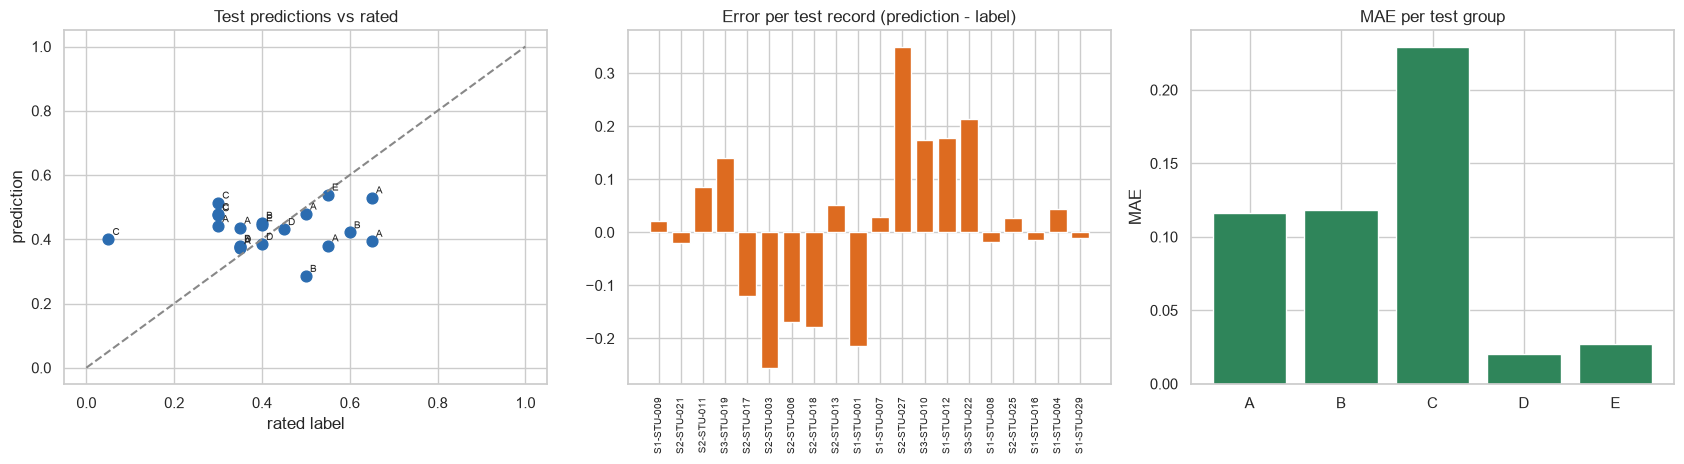

In [4]:
m = metrics(final.y, final.pred)
lo, hi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=5000)
rlo, rhi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.corrcoef(y, p)[0, 1], n=5000)
print(f"MAE {m['MAE']:.3f}  (95% CI {lo:.3f}-{hi:.3f})   RMSE {m['RMSE']:.3f}   median abs error {m['MedAE']:.3f}")
print(f"Pearson {m['pearson']:.3f} (95% CI {rlo:.3f}-{rhi:.3f})   Spearman {m['spearman']:.3f}   Kendall {m['kendall']:.3f}   R2 {m['R2']:.3f}   CCC {m['CCC']:.3f}")
print(f"ICC(2,1) {m['ICC2_1']:.3f}   ICC(3,1) {m['ICC3_1']:.3f}   bias {m['bias']:.3f}   calibration slope {m['calib_slope']:.2f} intercept {m['calib_intercept']:.2f}")
print(f"within 0.1: {m['within_0.1']:.0%}   rubric band exact {m['band_exact']:.0%}   within one band {m['band_within_1']:.0%}   weighted kappa {m['band_qwk']:.2f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(final.y, final.pred, s=60, color="#2b6cb0")
for r in final.itertuples():
    axes[0].annotate(r.group, (r.y, r.pred), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].plot([0, 1], [0, 1], "--", color="#888")
axes[0].set(title="Test predictions vs rated", xlabel="rated label", ylabel="prediction")
axes[1].bar(final.record_id.str.replace(r"^T\d+-", "", regex=True), final.pred - final.y, color="#dd6b20")
axes[1].set(title="Error per test record (prediction - label)")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
per_group = final.groupby("group").apply(lambda g: np.abs(g.pred - g.y).mean(), include_groups=False)
axes[2].bar(per_group.index, per_group.values, color="#2f855a")
axes[2].set(title="MAE per test group", ylabel="MAE")
plt.tight_layout()
plt.show()

## 4. Against the protocol's criteria

In [5]:
mean_p = base["mean"] if "mean" in base else base["always predict the mean"]
mean_mae = float(np.abs(mean_p.pred - mean_p.y).mean())
ref = base[CRIT["reference"]].sort_values("record_id").reset_index(drop=True)
mine = final.sort_values("record_id").reset_index(drop=True)
glo, ghi = paired_diff_bootstrap(mine.y.to_numpy(), ref.pred.to_numpy(), mine.pred.to_numpy(), mine.group.to_numpy(), n=5000)
mae_ref, mae_me = float(np.abs(ref.pred - ref.y).mean()), float(np.abs(mine.pred - mine.y).mean())
act = final[final.activity > 0]
mae_act = float(np.abs(act.pred - act.y).mean())
ratio = m["MAE"] / mean_mae


def row(name, value, minimum, target, ok_min, ok_target):
    return {"criterion": name, "result": value, "minimum (works)": minimum, "target": target, "meets minimum": bool(ok_min), "meets target": bool(ok_target)}


rows = [
    row("MAE / MAE of always predicting the mean", f"{ratio:.2f} ({m['MAE']:.3f} / {mean_mae:.3f})", f"<= {CRIT['mean_ratio'][0]}", f"<= {CRIT['mean_ratio'][1]}", ratio <= CRIT["mean_ratio"][0], ratio <= CRIT["mean_ratio"][1]),
    row("Pearson", f"{m['pearson']:.3f}", f">= {CRIT['corr'][0]}", f">= {CRIT['corr'][1]}", m["pearson"] >= CRIT["corr"][0], m["pearson"] >= CRIT["corr"][1]),
    row("Spearman", f"{m['spearman']:.3f}", f">= {CRIT['corr'][0]}", f">= {CRIT['corr'][2]}", m["spearman"] >= CRIT["corr"][0], m["spearman"] >= CRIT["corr"][2]),
    row(f"Beats {CRIT['reference_label']}", f"gain {mae_ref - mae_me:+.3f} (95% CI {glo:.3f} to {ghi:.3f})", "interval excludes 0", f"and >= {int(CRIT['beat_gain'] * 100)}% lower MAE",
        glo > 0, (glo > 0) and (mae_me <= (1 - CRIT["beat_gain"]) * mae_ref)),
    row("Bias", f"{m['bias']:+.3f}", f"within +-{CRIT['bias'][0]}", f"within +-{CRIT['bias'][1]}", abs(m["bias"]) <= CRIT["bias"][0], abs(m["bias"]) <= CRIT["bias"][1]),
    row("Calibration slope", f"{m['calib_slope']:.2f}", f"{CRIT['slope'][0][0]} - {CRIT['slope'][0][1]}", f"{CRIT['slope'][1][0]} - {CRIT['slope'][1][1]}",
        CRIT["slope"][0][0] <= m["calib_slope"] <= CRIT["slope"][0][1], CRIT["slope"][1][0] <= m["calib_slope"] <= CRIT["slope"][1][1]),
    row("Rubric bands within one", f"{m['band_within_1']:.0%}", f">= {CRIT['band_within'][0]:.0%}", f">= {CRIT['band_within'][1]:.0%}",
        m["band_within_1"] >= CRIT["band_within"][0], m["band_within_1"] >= CRIT["band_within"][1]),
]
if CRIT["band_exact"]:
    rows.append(row("Rubric bands exact", f"{m['band_exact']:.0%}", "-", f">= {CRIT['band_exact']:.0%}", True, m["band_exact"] >= CRIT["band_exact"]))
if CRIT["mae_active"]:
    rows.append(row("MAE, students with activity", f"{mae_act:.3f}", f"<= {CRIT['mae_active'][0]}", f"<= {CRIT['mae_active'][1]}", mae_act <= CRIT["mae_active"][0], mae_act <= CRIT["mae_active"][1]))
criteria = pd.DataFrame(rows).set_index("criterion")
works, target = bool(criteria["meets minimum"].all()), bool(criteria["meets target"].all())
print("meets every MINIMUM criterion:", works, "| meets every TARGET criterion:", target)
criteria

meets every MINIMUM criterion: False | meets every TARGET criterion: False


,result,minimum (works),target,meets minimum,meets target
criterion,,,,,
MAE / MAE of always predicting the mean,0.94 (0.116 / 0.124),<= 0.8,<= 0.65,False,False
Pearson,0.078,>= 0.5,>= 0.7,False,False
Spearman,0.003,>= 0.5,>= 0.7,False,False
Beats always predicting the mean,gain +0.008 (95% CI -0.014 to 0.027),interval excludes 0,and >= 20% lower MAE,False,False
Bias,+0.015,within +-0.05,within +-0.03,True,True
Calibration slope,0.18,0.5 - 1.5,0.8 - 1.2,False,False
Rubric bands within one,95%,>= 85%,>= 90%,True,True


## 5. Sanity checks

In [6]:
names = []
for c_, tf in PROPOSAL:
    names.append(c_)
coef = {}
for o, (model, alpha, n) in fits.items():
    r = model.named_steps["ridge"].coef_
    imputer = model.named_steps["simpleimputer"]
    cols = list(names) + [f"{n_}_missing" for n_ in np.array(names)[np.isnan(design(real[real.group != o], PROPOSAL)).any(axis=0)]]
    coef[o] = pd.Series(r[:len(cols)], index=cols[:len(r)])
coef = pd.DataFrame(coef).round(3)
print("standardised coefficients per fold (features oriented so that more means a higher score):")
print(coef.to_string())
neg = coef.loc[[c for c in coef.index if not c.endswith("_missing")]]
print("\nany negative coefficient on a proposal feature:", bool((neg < -1e-9).any().any()))

standardised coefficients per fold (features oriented so that more means a higher score):
                   A      B      C      D      E
TC_CB          0.007 -0.047 -0.109 -0.058 -0.024
TC_CB_missing -0.004 -0.000    NaN -0.007 -0.008
TC_DR          0.013  0.038  0.010  0.038  0.027
TC_DR_missing -0.004 -0.000    NaN -0.007 -0.008
TC_FI          0.021  0.041  0.078  0.061  0.039
TC_FI_missing -0.004 -0.000    NaN -0.007 -0.008
TC_SC          0.011  0.058 -0.048  0.017  0.016
TC_SP          0.013  0.029  0.096  0.042  0.027

any negative coefficient on a proposal feature: True


In [7]:
for model_name, g in test_table.iterrows():
    log_run(F, "06_final_test", model_name, "outer test groups, pooled (20 records)", {"MAE": round(g.MAE, 4), "RMSE": round(g.RMSE, 4), "pearson": round(g.Pearson, 4),
                                                                                      "spearman": round(g.Spearman, 4), "bias": round(g.bias, 4)})
final.to_csv(F.results / "final_test_predictions.csv", index=False)
criteria.to_csv(F.results / "final_test_criteria.csv")
print("saved")

saved


## 6. Reading the results

**The model:** Ridge on the five proposal features, trained on rated records only (`alpha` by leave-one-out), scored once on the held-out
test groups: 20 rated records, each predicted by a model that never saw that student.

| Metric (test) | Result | 95% interval |
|---|---|---|
| MAE | 0.116 | 0.050 - 0.175 |
| MAE as a share of always predicting the mean (0.124) | **0.94** | |
| Pearson / Spearman | **0.078** / 0.003 | -0.257 to 0.502 (Pearson) |
| R2 | -0.127 (worse than the mean) | |
| Bias | +0.015 | |
| Calibration slope | **0.18** | |
| Rubric band: exact / within one | 45% / 95% | |

**Against the protocol's criteria: the model does not work, as predicted.** It is 6% better than guessing the mean (the minimum was 20%),
the gain over the mean is +0.008 with an interval of -0.014 to +0.027, correlation with the rated label is 0.08 (needed 0.50), and the
calibration slope is 0.18: the predictions barely move with the label. Only bias and the within-one rubric band (95%, which the mean also
reaches) are met.

**Single features are no better.** Files involved alone scores 0.106 and story points alone 0.118, both with correlations below 0.3; subtasks
alone is worse than the mean.

**Sanity checks.** Several coefficients are negative in some folds (`CB` in four of five, `SC` in one), which is not meaningful: a larger
component breadth should not lower complexity. They reflect noise in a model with five features and 13-18 rated records.

**What can honestly be said**
1. Task Complexity cannot be learned from this dataset: 20 rated records, a label range of only 0.05-0.65, features that correlate 0.24-0.50
   with the label, and story points and subtasks taken from a reconstructed board.
2. This is a finding about data size and label quality, not about the proposal's idea. The code-derived features (files, dependency reach)
   carry more signal than the board features, which points to a design (measure complexity from the repository before the sprint, with
   lecturer-set story points) that needs more labels to test.
3. For the presentation: Task Complexity is the factor with the weakest evidence, and the honest result is that it is not yet demonstrated.

Saved: `training/results/final_test_predictions.csv`, `final_test_criteria.csv`.